# TP2 — Segmentation de la rate avec un U-Net 3D (corrigé)

Apprentissage profond en imagerie médicale — Master de mathématiques

**Mode d'emploi.** Le code est volontairement simple. Le drapeau `REDUIT` (cellule de configuration) choisit entre le protocole complet (GPU) et la version réduite (CPU). Les réponses aux questions ⋆ sont données dans des cellules Markdown ; celles qui dépendent des résultats numériques sont formulées comme *ce que l'on doit observer* et sont à confronter à vos propres sorties.

**Hypothèses sur les fichiers.**
- Les données sont dans `Task09_Spleen/` (`imagesTr/`, `labelsTr/`).
- `split_patients.csv` (issu du TP1) a les colonnes `image`, `label`, `split` (valeurs `train`, `val`, `test`). Si le fichier n'existe pas, la cellule A1 en crée un (60/20/20, graine fixée).

In [2]:
import os, time, glob, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy import ndimage, optimize
import glob, os
import nibabel as nib
import pandas as pd

from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
    Spacingd, ScaleIntensityRanged, CropForegroundd, SpatialPadd, RandCropByPosNegLabeld,
    RandSpatialCropd, RandAffined, RandGaussianNoised, RandScaleIntensityd, EnsureTyped)
from monai.data import CacheDataset, DataLoader
from monai.networks.nets import UNet
from monai.losses import DiceLoss, DiceCELoss
from monai.inferers import sliding_window_inference
from monai.utils import set_determinism

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("🚀 Utilisation du GPU Apple Silicon (MPS)")
else:
    device = torch.device("cpu")
    print("⚠️ MPS non disponible, utilisation du CPU")
print("device :", device)

# ------------------------- configuration -------------------------
REDUIT = (device.type == "cpu")      # mettre False pour forcer le protocole complet
SEED = 0
DATA_DIR = "Task09_Spleen"

REDUIT = True
if REDUIT:
    PIXDIM, PATCH = (3.0, 3.0, 3.0), (64, 64, 64)
    CHANNELS, STRIDES = (8, 16, 32, 64), (2, 2, 2)
    N_TRAIN, N_VAL, N_TEST = 10, 4, 4
    N_ITER, VAL_EVERY = 300, 50
else:
    PIXDIM, PATCH = (1.5, 1.5, 2.0), (96, 96, 96)
    CHANNELS, STRIDES = (16, 32, 64, 128, 256), (2, 2, 2, 2)
    N_TRAIN, N_VAL, N_TEST = None, None, None   # tout le jeu
    N_ITER, VAL_EVERY = 3000, 120               # ~ 5 passages sur 24 volumes = 120 iterations
NUM_SAMPLES = 2    # patchs par volume ; avec batch_size=1 on obtient un lot de 2 patchs (cf. B3)
print("version reduite :", REDUIT)

🚀 Utilisation du GPU Apple Silicon (MPS)
device : mps
version reduite : True


In [3]:
data_dir  = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA"
root = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen"


## 1. Pipeline de données

### A1. Listes de dictionnaires et vérification de la séparation par patient

In [4]:
root = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen"

rows = []
data_dicts = []
for img_path in sorted(glob.glob(os.path.join(root, "imagesTr", "*.nii.gz"))):
    name = os.path.basename(img_path)                      # ex : spleen_10.nii.gz
    lab_path = os.path.join(root, "labelsTr", name)
    #patient_id = name.replace(".nii.gz", "")               # ex : spleen_10

    data_dicts.append({"image": img_path, "label": lab_path} )


        

In [5]:
data_dir  = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA"

if os.path.exists("split_patients.csv"):
    df = pd.read_csv("split_patients.csv")
else:
    root = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen"
    
    rows = []
    data_dicts = []
    for img_path in sorted(glob.glob(os.path.join(root, "imagesTr", "*.nii.gz"))):
        name = os.path.basename(img_path)                      # ex : spleen_10.nii.gz
        lab_path = os.path.join(root, "labelsTr", name)
        patient_id = name.replace(".nii.gz", "")               # ex : spleen_10

        data_dicts.append({"image": img_path, "label": lab_path} )
    
        img_nii = nib.load(img_path)                           # lecture de l'en-tête (rapide)
        shape = img_nii.shape
        spacing = tuple(float(s) for s in img_nii.header.get_zooms()[:3])
    
        lab = np.asarray(nib.load(lab_path).dataobj)           # masque (0 = fond, 1 = rate)
        n_vox = int((lab > 0).sum())
        vol_ml = n_vox * np.prod(spacing) / 1000.0             # mm^3 -> mL
    
        rows.append({
            "patient_id": patient_id,
            "n_coupes": shape[2],
            "espacement_x": spacing[0],
            "espacement_y": spacing[1],
            "espacement_z": spacing[2],
            "volume_organe_ml": vol_ml,
            "image": img_path,
            "label": lab_path,
        })
        
    
    df = pd.DataFrame(rows)
    print(df.shape)
    



(41, 8)


In [4]:
print(df.shape)   
df.head()

(41, 8)


,patient_id,n_coupes,espacement_x,espacement_y,espacement_z,volume_organe_ml,image,label
0,spleen_10,55,0.976562,0.976562,5.0,253.062001,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
1,spleen_12,168,0.753906,0.753906,1.5,458.409483,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
2,spleen_13,77,0.742188,0.742188,2.5,280.796347,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
3,spleen_14,54,0.851562,0.851562,5.0,450.188889,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
4,spleen_16,61,0.792969,0.792969,8.0,201.437279,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...


In [5]:
data_dicts

[{'image': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/imagesTr/spleen_10.nii.gz',
  'label': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/labelsTr/spleen_10.nii.gz'},
 {'image': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/imagesTr/spleen_12.nii.gz',
  'label': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/labelsTr/spleen_12.nii.gz'},
 {'image': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/imagesTr/spleen_13.nii.gz',
  'label': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/labelsTr/spleen_13.nii.gz'},
 {'image': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/imagesTr/spleen_14.nii.g

In [6]:
# Structure des données sous forme de dictionnaire Python
#train_images = sorted(glob.glob(os.path.join(root, "imagesTr", "*.nii.gz")))
#train_labels = sorted(glob.glob(os.path.join(root, "labelsTr", "*.nii.gz")))

n = df["patient_id"].shape[0]
train_ids, tmp_ids = train_test_split(range(n), test_size=0.4, random_state=SEED)
val_ids, test_ids  = train_test_split(tmp_ids,  test_size=0.5, random_state=SEED)


train_files = [data_dicts[i] for i in train_ids]
val_files = [data_dicts[i] for i in val_ids]
test_files = [data_dicts[i] for i in test_ids]

### A2. Chaînes de transformations MONAI

Justification des paramètres :
- **Orientation RAS** : tous les volumes ont les mêmes axes, donc une même signification anatomique des axes pour le réseau et pour les augmentations.
- **Espacement (1,5 ; 1,5 ; 2,0) mm** : les volumes CT du Décathlon sont très anisotropes (≈ 0,8 mm dans le plan, jusqu'à 5 mm entre coupes). On rééchantillonne vers un pas commun, proche de la résolution native, ce qui rend les distances comparables d'un patient à l'autre ; plus fin = mémoire ×8 pour un gain négligeable sur un organe de la taille de la rate. Interpolation trilinéaire pour l'image (valeurs continues), plus proche voisin pour le masque (on ne doit pas créer de valeurs intermédiaires).
- **Fenêtre [−57, 164] HU → [0, 1]** : elle couvre les tissus mous (rate ≈ 40–120 HU selon le produit de contraste) et écrase l'os, l'air et le métal, qui ne servent pas à la tâche. Cela fixe aussi l'échelle d'entrée du réseau.
- **Patch 96³** : 96 × 1,5 = 144 mm (plan) et 96 × 2 = 192 mm (axe) : un patch peut contenir toute la rate (≈ 10–15 cm) avec du contexte, tout en tenant en mémoire GPU avec un lot de 2. Un patch plus petit verrait des rates tronquées, plus grand ne tiendrait pas en mémoire.
- **`pos=1, neg=1`** : un patch sur deux est centré sur un voxel du premier plan (voir A4).

In [6]:
KEYS = ["image", "label"]
common = [
    LoadImaged(keys=KEYS),
    EnsureChannelFirstd(keys=KEYS),
    Orientationd(keys=KEYS, axcodes="RAS"),
    Spacingd(keys=KEYS, pixdim=PIXDIM, mode=("bilinear", "nearest")),
    ScaleIntensityRanged(keys=["image"], a_min=-57, a_max=164, b_min=0.0, b_max=1.0, clip=True),
    CropForegroundd(keys=KEYS, source_key="image", allow_smaller=True),  # le recadrage n'utilise que l'image
]


nvImageCodec is not available; skipping pydicom decoder plugin registration.
NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.


### A3. Augmentations plausibles pour la rate

| Augmentation | Verdict | Justification |
|---|---|---|
| Miroir gauche/droite | **À éviter** (ou à tester avec prudence) | La rate est à gauche du patient ; une image miroir place la rate à droite, du côté du foie : anatomie impossible (hors *situs inversus*). Le réseau y gagne en variété mais perd un a priori utile et risque de confondre foie et rate. |
| Miroir haut/bas | **Non** | Patient toujours en décubitus, tête en haut : une image à l'envers n'apparaît jamais. |
| Rotation de 90° | **Non** | Idem : l'orientation du corps est standardisée (RAS). |
| Rotation de ±15° | **Oui** | Reproduit la variabilité de posture / d'inclinaison du patient. |
| Bruit gaussien | **Oui** (faible) | Reproduit la variabilité du bruit de reconstruction / de dose. |
| Variation d'intensité / de contraste | **Oui** (modérée) | Reproduit la variabilité de rehaussement (phase d'injection, produit de contraste). Pas trop forte : les HU sont quantitatifs. |
| Déformation élastique forte | **Non** (faible : oui) | Une forte déformation crée des formes d'organe irréalistes ; une déformation légère imite la variabilité anatomique. |

In [7]:
# Augmentation de donnees pour l'ensemble d'entrainement
train_transform = Compose(common + [
    SpatialPadd(keys=["image", "label"], spatial_size=PATCH),   # au cas où un volume est plus petit que le patch
    RandCropByPosNegLabeld(keys=["image", "label"], label_key="label", spatial_size=PATCH,
                           pos=1, neg=1, num_samples=NUM_SAMPLES, image_key="image", image_threshold=0),
    RandAffined(keys=["image", "label"], prob=0.2, rotate_range=(np.pi / 12,) * 3, scale_range=(0.1,) * 3,
                mode=("bilinear", "nearest"), padding_mode="border"),   # pi/12 = 15 degrés
    RandGaussianNoised(keys=["image"], prob=0.2, std=0.01),
    RandScaleIntensityd(keys=["image"], factors=0.1, prob=0.5),
    EnsureTyped(keys=["image", "label"]),
])
# Pas d'augmentation de donnees pour l'ensemble de validation
val_transform = Compose(common + [EnsureTyped(keys=["image", "label"])])

In [9]:
#import monai
#dataset = monai.apps.DecathlonDataset(
#    root_dir=data_dir, task="Task09_Spleen", section="training", transform=train_transform, download=True
#)
#data_loader = monai.data.DataLoader(dataset, batch_size=1, shuffle=True, num_workers=1)

### A4⋆. Échantillonnage des patchs : proportion de premier plan

In [8]:
set_determinism(seed=SEED)

vol = Compose(common)(data_dicts[0])
#vol = Compose(common)({"image": df["image"].iloc[0],"label": df["label"].iloc[0]})       # un volume d'apprentissage prétraité
print("forme du volume (canal, x, y, z) :", tuple(vol["image"].shape))

fg_total = float((vol["label"] > 0).float().mean())
print(f"proportion de premier plan dans le volume entier : {fg_total:.4f}")

# (i) patchs tirés uniformément
unif = RandSpatialCropd(keys=["image", "label"], roi_size=PATCH, random_size=False)
prop_unif = []
for _ in range(100):
    p = unif(SpatialPadd(keys=["image", "label"], spatial_size=PATCH)(vol))
    prop_unif.append(float((p["label"] > 0).float().mean()))

# (ii) patchs avec pos=1, neg=1
posneg = RandCropByPosNegLabeld(keys=["image", "label"], label_key="label", spatial_size=PATCH,
                                pos=1, neg=1, num_samples=100, image_key="image", image_threshold=0)
patchs = posneg(SpatialPadd(keys=["image", "label"], spatial_size=PATCH)(vol))
prop_pn = [float((p["label"] > 0).float().mean()) for p in patchs]

print(f"uniforme : moyenne {np.mean(prop_unif):.4f}, patchs sans aucun premier plan : {np.mean(np.array(prop_unif) == 0):.0%}")
print(f"pos=1,neg=1 : moyenne {np.mean(prop_pn):.4f}, patchs sans aucun premier plan : {np.mean(np.array(prop_pn) == 0):.0%}")

forme du volume (canal, x, y, z) : (1, 164, 141, 91)
proportion de premier plan dans le volume entier : 0.0044
uniforme : moyenne 0.0131, patchs sans aucun premier plan : 39%
pos=1,neg=1 : moyenne 0.0229, patchs sans aucun premier plan : 19%


(1, 164, 141, 91)


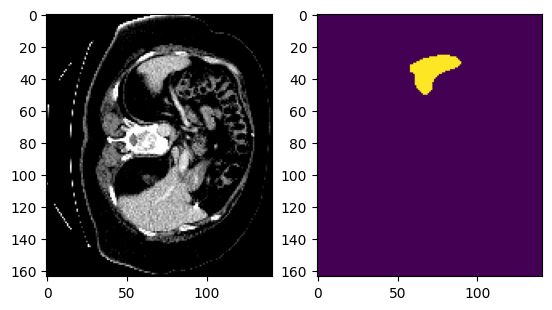

unique labels: [0. 1.]


In [9]:
vol_shape = vol["image"].detach().cpu().numpy().shape
print(vol_shape)

plt.subplots(1, 2)
plt.subplot(1, 2, 1)
plt.imshow(vol["image"].detach().cpu().numpy()[0,:,:,vol_shape[3]//2], cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(vol["label"].detach().cpu().numpy()[0,:,:,vol_shape[3]//2])
plt.show()

print(f"unique labels: {np.unique(vol['label'].detach().cpu().numpy())}")

**Réponses A4⋆.**
- Avec le tirage uniforme, la proportion de premier plan dans un patch est de l'ordre de celle du volume (quelques %), et une partie des patchs n'en contient aucun. Avec `pos=1, neg=1`, un patch sur deux est centré sur un voxel de rate : la proportion moyenne est nettement plus élevée (de l'ordre de 10 à 20 %).
- **Perte avec (i) seul** : la perte (entropie croisée moyennée sur les voxels) est dominée par le fond ; le gradient issu des quelques voxels de rate est noyé. Dans les patchs sans rate, le meilleur comportement est de prédire « fond » partout, ce qui renforce la solution triviale (voir C4). Pour la perte de Dice calculée par patch, un patch sans premier plan donne $\mathcal L = 1 - 0/(\sum p)=1$ dès qu'on prédit un seul voxel positif (gradient peu informatif et instable).
- **Effet de pos/neg sur la probabilité prédite** : le suréchantillonnage change la proportion de positifs vue à l'entraînement, de $\pi$ (réelle) à $\pi_{\text{train}}$ plus grand. Le réseau apprend donc une probabilité *biaisée vers le haut* (décalage de prior) : en logit, $\text{logit}\,p_{\text{vrai}} \approx \text{logit}\,p_{\text{prédit}} + \log\frac{\pi/(1-\pi)}{\pi_{\text{train}}/(1-\pi_{\text{train}})}$. Les probabilités ne sont pas calibrées pour la population réelle (utile pour F2–F4) ; l'argmax est en revanche peu affecté si le modèle est discriminant.

## 2. Modèle

### B1. U-Net 3D

Comment fonctionne CacheDataset ?
- Au tout premier démarrage (avant l'époque 1), CacheDataset parcourt votre jeu de données, applique toutes vos transformations lourdes (définies dans votre Compose), et stocke les résultats directement en mémoire vive (RAM).

- Pendant l'entraînement, au lieu de recharger et de transformer les fichiers sur le disque, il va simplement piocher les données déjà prêtes et pré-calculées directement dans la RAM.

In [12]:
# Utilisation de CacheDataset pour accélérer les I/O
train_ds = CacheDataset(data=train_files, transform=train_transform, cache_rate=1.0, num_workers=4)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)

val_ds = CacheDataset(data=val_files, transform=val_transform, cache_rate=1.0, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=2)

Loading dataset: 100%|███████████████████████████████████████████████████████████████████| 8/8 [00:04<00:00,  1.87it/s]


In [13]:
import torch
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

def make_model():
    # Détection automatique du périphérique (Mac M3 MPS, CUDA ou CPU)
    
    
    # Création du modèle U-Net 3D (2 classes : 0=Fond, 1=Rate)
    model = UNet(
        spatial_dims=3,
        in_channels=1,
        out_channels=2,
        channels=CHANNELS,
        strides=STRIDES,
        num_res_units=2,
        norm=Norm.BATCH,
    ).to(device)
    
    return model
    
# Modèle UNet 3D MONAI
model = make_model()

# Combinaison Dice + Entropie Croisée (Loss hybride)
loss_function = DiceCELoss(to_onehot_y=True, softmax=True)

# Optimiseur et Métrique de calcul
optimizer = torch.optim.Adam(model.parameters(), 1e-3)
dice_metric = DiceMetric(include_background=False, reduction="mean")


### Boucle d'entrainement

In [14]:
from monai.transforms import AsDiscrete


post_pred = AsDiscrete(argmax=True, to_onehot=2)
post_label = AsDiscrete(to_onehot=2)

max_epochs = 50
best_val_dice = -1.0

for epoch in range(max_epochs):
    model.train()
    epoch_loss = 0
    for batch_data in train_loader:
        inputs, labels = batch_data["image"].to(device), batch_data["label"].to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print(f"Epoch {epoch + 1}/{max_epochs} - Loss: {epoch_loss / len(train_loader):.4f}")

    # Évaluation avec Sliding Window (Inférence par fenêtre glissante sur les volumes 3D entiers)
    if (epoch + 1) % 5 == 0:
        model.eval()
        with torch.no_grad():
            for val_data in val_loader:
                val_inputs, val_labels = val_data["image"].to(device), val_data["label"].to(device)
                
                # Fenêtre glissante adaptée à la taille des patchs (96x96x96)
                val_outputs = sliding_window_inference(
                    inputs=val_inputs, roi_size=PATCH, sw_batch_size=4, predictor=model
                )
                
                # Post-processing pour la métrique
                val_outputs = [post_pred(i) for i in val_outputs]
                val_labels = [post_label(i) for i in val_labels]
                
                dice_metric(y_pred=val_outputs, y=val_labels)

            mean_dice = dice_metric.aggregate().item()
            dice_metric.reset()

            print(f"---> Validation Mean Dice Score: {mean_dice:.4f}")
            if mean_dice > best_val_dice:
                best_val_dice = mean_dice
                torch.save(model.state_dict(), os.path.join(root, "best_metric_model.pth"))
                print("Modèle sauvegardé !")

Epoch 1/50 - Loss: 1.2723
Epoch 2/50 - Loss: 1.0247
Epoch 3/50 - Loss: 0.8525
Epoch 4/50 - Loss: 0.7450
Epoch 5/50 - Loss: 0.6671
---> Validation Mean Dice Score: 0.0343
Modèle sauvegardé !
Epoch 6/50 - Loss: 0.6038
Epoch 7/50 - Loss: 0.5552
Epoch 8/50 - Loss: 0.4821
Epoch 9/50 - Loss: 0.4781
Epoch 10/50 - Loss: 0.4024
---> Validation Mean Dice Score: 0.5598
Modèle sauvegardé !
Epoch 11/50 - Loss: 0.3225
Epoch 12/50 - Loss: 0.3615
Epoch 13/50 - Loss: 0.3386
Epoch 14/50 - Loss: 0.3018
Epoch 15/50 - Loss: 0.3036
---> Validation Mean Dice Score: 0.7090
Modèle sauvegardé !
Epoch 16/50 - Loss: 0.2792
Epoch 17/50 - Loss: 0.2791
Epoch 18/50 - Loss: 0.2095
Epoch 19/50 - Loss: 0.2647
Epoch 20/50 - Loss: 0.2953
---> Validation Mean Dice Score: 0.7638
Modèle sauvegardé !
Epoch 21/50 - Loss: 0.2791
Epoch 22/50 - Loss: 0.2402
Epoch 23/50 - Loss: 0.2196
Epoch 24/50 - Loss: 0.2261
Epoch 25/50 - Loss: 0.3068
---> Validation Mean Dice Score: 0.0830
Epoch 26/50 - Loss: 0.4012
Epoch 27/50 - Loss: 0.2915


### Evaluation du modele

Ici on peut evaluer sur l'ensemble de validation. Je l'ai fait sur l'ensemble de test. A revoir! 

In [15]:
vol_test = Compose(common)(test_files[1])
sh = vol_test["image"].shape

In [16]:
import matplotlib.pyplot as plt
import torch

# Passage du modèle en mode évaluation
model.eval()

with torch.no_grad():
    # Prenons un exemple du DataLoader de validation
    #val_data = next(iter(val_loader)) 
    #val_inputs, val_labels = val_data["image"].to(device), val_data["label"].to(device)
    test_inputs, test_labels = vol_test["image"].unsqueeze(1).to(device), vol_test["label"].unsqueeze(1).to(device)
    
    # Inférence par fenêtre glissante
    test_outputs = sliding_window_inference(
        inputs=test_inputs, 
        roi_size=PATCH, 
        sw_batch_size=4, 
        overlap = .5,
        mode = "gaussian",
        predictor=model
    )
    
    # Conversion des prédictions (argmax pour obtenir l'indice de classe)
    print(test_outputs.shape)
    pred_mask = torch.argmax(test_outputs, dim=1).detach().cpu().numpy()
    true_mask = test_labels.detach().cpu().numpy()
    img_np = test_inputs.detach().cpu().numpy()

torch.Size([1, 2, 109, 81, 164])


In [17]:
print(true_mask.shape)
print(pred_mask.shape)

slice_sums = np.sum(true_mask.squeeze() > 0, axis=(0,1)) # Somme sur ...

# 2. Trouver l'indice de la tranche avec la plus grande quantité de tissu
max_slice_idx = np.argmax(slice_sums)
print(max_slice_idx)

(1, 1, 109, 81, 164)
(1, 109, 81, 164)
128


1.0
1


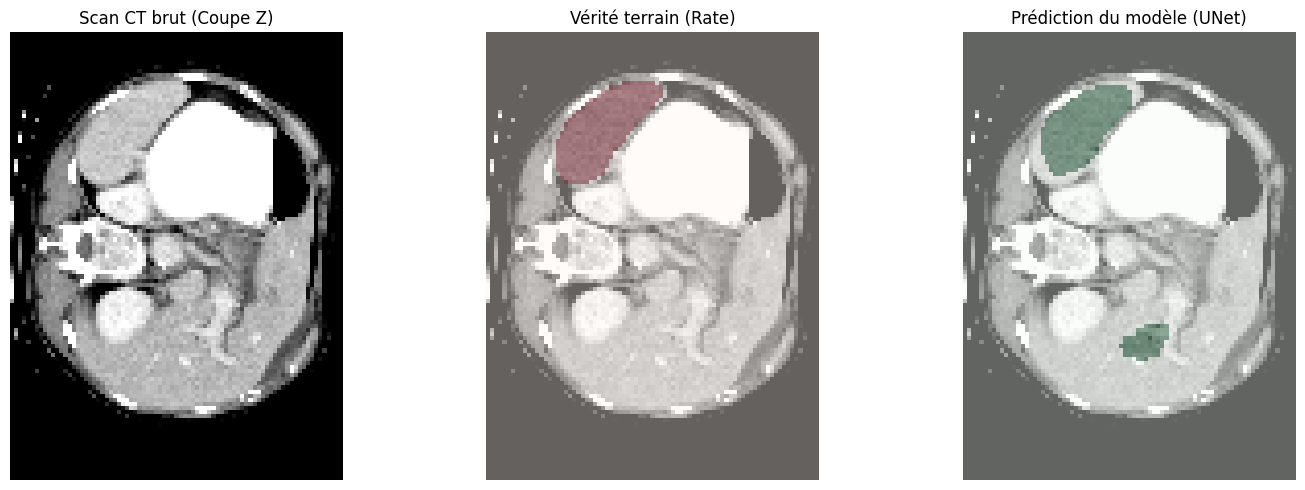

In [18]:
# Les données ont la forme (Batch, Canal, Profondeur, Hauteur, Largeur) -> on prend le premier batch (index 0)
# et on extrait une coupe au milieu de l'axe Z (profondeur)
slice_idz = max_slice_idx

ct_slice = img_np[0, 0,  :, :, slice_idz]
true_slice = true_mask[0, 0,  :, :, slice_idz]
print(np.max(true_slice))
pred_slice = pred_mask[0,  :, :, slice_idz]
print(np.max(pred_slice))

# --- Affichage avec Matplotlib ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Scan CT seul
axes[0].imshow(ct_slice, cmap="gray")
axes[0].set_title("Scan CT brut (Coupe Z)")
axes[0].axis("off")

# 2. Vérité terrain (Ground Truth) superposée
axes[1].imshow(ct_slice, cmap="gray")
axes[1].imshow(true_slice, cmap="Reds", alpha=0.4)  # alpha gère la transparence
axes[1].set_title("Vérité terrain (Rate)")
axes[1].axis("off")

# 3. Prédiction du modèle superposée
axes[2].imshow(ct_slice, cmap="gray")
axes[2].imshow(pred_slice, cmap="Greens", alpha=0.4)
axes[2].set_title("Prédiction du modèle (UNet)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [19]:
test_ds = CacheDataset(data=test_files, transform=val_transform, cache_rate=1.0, num_workers=4)
test_loader = DataLoader(test_ds, batch_size=1, num_workers=2)

with torch.no_grad():
    for test_data in test_loader:
        test_inputs, test_labels = test_data["image"].to(device), test_data["label"].to(device)
        
        # Fenêtre glissante adaptée à la taille des patchs (96x96x96)
        test_outputs = sliding_window_inference(
            inputs=test_inputs, roi_size=PATCH, sw_batch_size=4, predictor=model
        )
        
        # Post-processing pour la métrique
        test_outputs = [post_pred(i) for i in test_outputs]
        test_labels = [post_label(i) for i in test_labels]
        
        dice_metric(y_pred=test_outputs, y=test_labels)

    mean_dice = dice_metric.aggregate().item()
print(f"🎯 Score Dice final sur l'ensemble de test : {mean_dice:.4f}")

Loading dataset: 100%|███████████████████████████████████████████████████████████████████| 9/9 [00:04<00:00,  2.13it/s]


🎯 Score Dice final sur l'ensemble de test : 0.7364


**Réponse B2⋆.** On trouve successivement $r = 6, 16, 36, 76$ à la sortie des quatre pooling (sauts $j = 2, 4, 8, 16$), puis $r = 76 + 2\cdot 2\cdot 16 = 140$ voxels au goulot.

- 140 voxels **dépasse** la taille du patch (96) : un voxel du goulot « voit » en théorie plus que le patch entier, donc une partie de son champ réceptif tombe sur le **remplissage par zéros** des bords. (Le champ réceptif *effectif* est plus petit que le théorique, concentré au centre.)
- Par rapport au volume : dans le plan, un volume prétraité fait plusieurs centaines de voxels à 1,5 mm ; 140 voxels (210 mm) ne couvrent qu'une partie du corps. Selon l'axe z, l'étendue dépend du nombre de coupes d'origine (comparer avec la forme affichée ci-dessus) ; elle est souvent du même ordre que 140 voxels, donc le champ réceptif peut y couvrir presque tout le volume.
- **Conséquence pour l'inférence** : près du bord d'un patch, le contexte est tronqué (zéros de remplissage) et les prédictions sont moins fiables. D'où le recouvrement des fenêtres et la pondération gaussienne, qui donne peu de poids aux bords (voir D4).

### B3⋆. Pourquoi la normalisation d'instance plutôt que par lot ?
Avec un lot de 2 patchs, les statistiques (moyenne, variance) calculées par la normalisation par lot sont **très bruitées** et sensibles à la composition du lot (un patch avec rate, un sans) ; les deux patchs d'un même volume sont de plus fortement corrélés. De plus, les statistiques de l'entraînement (moyennes mobiles) diffèrent de celles calculées à l'inférence sur des fenêtres glissantes, d'où un décalage entre entraînement et test. La normalisation d'instance (ou de groupe) calcule les statistiques par échantillon (et par canal), indépendamment de la taille du lot et sans différence entre entraînement et inférence.

**Dérivation.** Avec $I=\sum_i p_i g_i$ et $U=\sum_i p_i+\sum_i g_i$, on a $\partial I/\partial p_j = g_j$ et $\partial U/\partial p_j = 1$, donc
$\dfrac{\partial \mathcal L}{\partial p_j} = -2\,\dfrac{g_j U - I}{U^2}$.
Comme $I \le U/2 < U$, on a $U - I > 0$ : le gradient est **négatif** pour un voxel de rate ($g_j=1$), donc la descente de gradient augmente $p_j$ ; il est **positif** pour un voxel de fond ($g_j=0$) : $+2I/U^2$, d'autant plus fort que le recouvrement $I$ est déjà élevé. Le gradient du Dice dépend de **toutes** les prédictions via $I$ et $U$ (perte *globale*), contrairement à l'entropie croisée, somme de termes indépendants par voxel.

La différence avec MONAI (avec lissage) est de l'ordre de $10^{-6}$ ; sans lissage elle est nulle.

**Remarque????** Les pertes d'entraînement des trois modèles ne sont pas comparables entre elles (échelles différentes) ; seul le Dice de validation, calculé de la même façon, l'est. On attend : l'entropie croisée seule démarre lentement (le fond domine) ; les pertes contenant du Dice montent plus vite ; Dice + entropie croisée est typiquement le plus stable.

### C4⋆. Déséquilibre et entropie croisée

**Commentaire.** La reconstruction du modèle identité est exacte à la précision machine ($\sim 10^{-16}$) avec ou sans pondération, et aussi pour un volume plus petit que la fenêtre (grâce au remplissage puis au recadrage). La moyenne pondérée $\hat p(v)=\sum_j w_j(v)p^{(j)}(v)/\sum_j w_j(v)$ est en effet un barycentre des prédictions : si toutes valent la même valeur $c$ en $v$, le résultat est $c$. Les petits écarts avec MONAI viennent de détails (normalisation et plancher des poids gaussiens, ordre des opérations) ; ils sont très faibles et n'altèrent presque pas le masque.

### D3. Plus grande composante connexe (connectivité 26)

Les valeurs correspondent à la théorie à la discrétisation près : pour deux surfaces identiques décalées de $d$, la distance de Hausdorff vaut $d$, et la distance moyenne de surface vaut environ $d/2$ (la distance en un point de la sphère est $\approx d|\cos\theta|$, de moyenne $d/2$).

### E2. Métriques par patient, avec et sans post-traitement

**Lecture attendue.** Le post-traitement améliore surtout HD95 et ASSD (suppression des îlots de faux positifs éloignés) avec un effet minime sur le Dice. Avec la perte d'entropie croisée seule, les faux positifs isolés sont plus fréquents ; les modèles avec Dice sont plus « francs » mais plus sujets à des faux positifs de grande taille. La variabilité entre patients (largeur des boîtes, valeurs aberrantes) est plus grande que la différence entre pertes : d'où l'intérêt de regarder la distribution et pas seulement la moyenne.

### E3. Volumes prédits vs de référence, Bland–Altman

**Réponse E3.** Le biais est la moyenne de « prédit − référence » ; il est significatif s'il est grand devant l'écart-type divisé par $\sqrt n$ (avec seulement quelques patients de validation, la conclusion reste fragile : calculer un intervalle de confiance sur le biais). On peut observer un léger biais **négatif** des modèles pénalisés par le Dice ou post-traités (sous-segmentation des bords) et un biais **positif** possible pour l'entropie croisée avec suréchantillonnage du premier plan (probabilités biaisées vers le haut, cf. A4). Regarder aussi si l'erreur dépend du volume (dérive sur le diagramme de Bland–Altman).

### E4⋆. Dice et distances : deux masques de référence

**Réponse E4⋆.**
- Le masque **décalé** a un Dice sensiblement inférieur à 1, et HD et HD95 valent environ le décalage (quelques mm) : tous les points sont également affectés.
- Le masque **correct + îlot** a un Dice quasiment parfait (l'îlot est minuscule en volume), mais une distance de Hausdorff (maximum) énorme, égale à la distance de l'îlot à l'organe, alors que HD95 reste presque nulle (l'îlot ne représente que quelques % des points de surface). Le Dice est donc aveugle aux petites erreurs lointaines, HD au maximum est ultra-sensible à un seul point, HD95 est un compromis (mais devient sensible si l'îlot dépasse 5 % des points de surface).
- **Radiothérapie** : une erreur locale peut irradier un organe à risque, donc des métriques de distance (HD95 voire HD maximum, NSD à 1–2 mm) pour la sécurité, ou le *Dice de surface* qui mesure la fraction de contour à corriger manuellement. **Mesure de volume** : le Dice est moins adapté ; on prend directement l'erreur de volume (absolue et relative), qui est ce qui compte, avec éventuellement le Dice comme contrôle de localisation.

### E5⋆. Espace rééchantillonné et évaluation « officielle »
- **Pourquoi l'espace rééchantillonné.** Les distances en mm et les volumes ne sont comparables entre patients qu'avec un espacement commun ; le recouvrement lui-même dépend de l'échantillonnage (un voxel de 5 mm ne représente pas la même chose qu'un voxel de 0,8 mm). On calcule donc les métriques dans un espace avec un espacement connu et isotrope ou fixé.
- **Précaution pour une évaluation officielle.** Les métriques officielles se calculent dans l'espace **original** de l'image (ou du masque de référence) : on doit rééchantillonner la prédiction vers la grille d'origine (plus proche voisin pour un masque ; ou, mieux, interpoler les probabilités avant seuillage), avec l'inversion exacte de toutes les transformations (orientation, recadrage, espacement). Sinon l'erreur d'interpolation du masque de référence (rééchantillonné à 1,5 mm) fausse l'estimation, notamment des distances de surface et des petites structures. On ne doit jamais comparer à un masque de référence rééchantillonné de manière différente de celle du protocole officiel.

## 6. Confiance, calibration et seuil

### F1. Histogrammes des probabilités de premier plan

**Réponse F1.** Le modèle le plus « tranché » (la plus petite fraction de voxels avec une probabilité intermédiaire) est typiquement celui qui utilise la **perte de Dice seule** : cette perte ne pénalise pas la confiance excessive, car elle ne dépend que des recouvrements ; l'entropie croisée est la plus étalée (elle est une règle de score propre, qui incite à des probabilités calibrées).

### F2. Diagramme de fiabilité et ECE (région d'intérêt)

**Lecture.** Les courbes sous la diagonale indiquent une sur-confiance (probabilité prédite supérieure à la fréquence observée), au-dessus une sous-confiance. Restreindre à la région d'intérêt est nécessaire : sur le volume entier, l'immense fond trivial (p ≈ 0, fréquence ≈ 0) rendrait l'ECE artificiellement petit. On attend l'ECE le plus faible pour l'entropie croisée et le plus élevé pour le Dice seul.

### F3. Seuil de décision

**Étape 1 : simulation sur données synthétiques.** Si les probabilités sont calibrées ($y\sim\text{Bernoulli}(p)$), le seuil qui maximise le score $F_1$ (équivalent au Dice global) vérifie $t^\star = F^\star/2$.

**Étape 2 : modèle entraîné avec l'entropie croisée.**

**Réponse F3.** Dans la simulation le seuil optimal coïncide avec $F^\star/2$ (la règle est exacte pour des probabilités calibrées et un score global ; on la démontre en annulant la dérivée de $F_1$ par rapport au seuil). Pour le modèle réel, $F^\star$ vaut environ 0,9–0,95, donc $F^\star/2\approx 0{,}45$–$0{,}48$, proche de 0,5 : le seuil optimal est proche de 0,5 et la courbe est très plate autour, de sorte que l'effet du seuil est faible quand le modèle est discriminant. L'écart à la règle s'explique par (i) le biais de calibration dû à `pos/neg` (A4), (ii) le Dice moyenné par patient et non global, (iii) le petit nombre de patients.

### F4. Mise à l'échelle de la température

**Réponse F4.** Pour deux classes, $\text{softmax}(z/T)_1 = \sigma((z_1-z_0)/T)$ : diviser les logits par $T>0$ ne change **pas le signe** de $z_1-z_0$, donc l'argmax (le masque) et le Dice sont **inchangés** ; seules les probabilités sont modifiées ($T>1$ adoucit, $T<1$ durcit). L'ECE s'améliore généralement. Deux précautions : la NLL sur tous les voxels est dominée par le fond trivial (on peut aussi l'estimer sur la région d'intérêt) ; et $T$ doit être ajusté sur un ensemble de validation et évalué sur un autre (ici, pour un seul paramètre, le risque de sur-ajustement est faible mais non nul).

### F5⋆. Sur-confiance de la perte de Dice
Le Dice ne mesure que le **recouvrement** : une fois un voxel classé du bon côté de 0,5, pousser sa probabilité vers 0 ou 1 améliore encore un peu le numérateur et le dénominateur, et il n'y a aucune pénalité pour une erreur confiante autre que son effet sur le recouvrement. Ce n'est pas une règle de score propre (contrairement à l'entropie croisée, minimisée en moyenne par la vraie probabilité conditionnelle). Les sorties se concentrent donc vers 0 et 1 : sur-confiance, probabilités peu informatives.

**Conséquence pour l'incertitude (CM5).** On ne peut pas interpréter naïvement la probabilité de sortie d'un modèle entraîné au Dice comme une incertitude : l'incertitude est concentrée aux frontières et les erreurs globales ne sont pas signalées. Il faut recalibrer (température, Platt par voxel), utiliser des méthodes de type ensembles ou *dropout* de Monte-Carlo, ou entraîner avec une perte propre (Dice + entropie croisée aide), et valider la qualité de l'incertitude (ECE dans la région d'intérêt, corrélation avec l'erreur).

## 7. Analyse des erreurs

### G1. Les trois patients de validation les moins bien segmentés

**À décrire pour chaque patient** (en regardant plusieurs coupes, pas seulement une) : faux positifs isolés (îlots dans un autre organe) ; sous-segmentation d'une extrémité (le pôle supérieur ou inférieur de la rate, le plus mal contrasté) ; fuite dans un organe voisin (estomac, rein gauche, queue du pancréas, mêmes niveaux de gris en CT) ; masque vide (rate non détectée) ; erreur d'annotation possible (le contour de référence franchit l'organe ou s'arrête brutalement). Les cas les plus fréquents pour la rate sont les rates très petites ou très volumineuses (splénomégalie), un contraste atypique, et des organes voisins de mêmes HU.

### G2. Dice en fonction du volume de l'organe

**Réponse G2.** Pour un petit organe, une erreur de quelques voxels sur la frontière représente une grande part du volume : le Dice, qui est une métrique relative au volume, est donc plus bas et plus variable. On attend une corrélation positive entre le volume et le Dice ; elle est à confirmer sur votre échantillon, qui est petit (quelques points ne permettent pas de conclusion forte).

### G3⋆. Synthèse
- **Choix de la perte.** (i) *Volumétrie* : Dice + entropie croisée (ou entropie croisée avec un seuil ajusté) ; on regarde l'erreur de volume et l'absence de biais. (ii) *Détection* : une perte à base de Dice (ou Dice + entropie croisée, avec un suréchantillonnage fort du premier plan) pour ne pas manquer de petits objets, quitte à tolérer des faux positifs que l'on filtre ensuite. (iii) *Probabilités calibrées* : l'entropie croisée, éventuellement suivie d'une mise à l'échelle de température.
- **Limites de l'évaluation.** Très peu de patients en validation (8 en protocole complet, 4 en version réduite) : intervalles de confiance larges, comparaisons de pertes à prendre avec prudence ; un seul annotateur par volume (la variabilité inter-experts est une borne naturelle du Dice) ; un seul centre / un seul type de scanner (pas de test de décalage de domaine) ; un seul entraînement par perte (variance liée à la graine non estimée) ; sélection du meilleur point de contrôle sur la validation (optimiste).
- **Protocole pour estimer correctement l'erreur de généralisation.** Séparation par patient ; tous les choix (perte, seuil, post-traitement, température) fixés sur la validation ; **un seul** passage sur un jeu de test intact ; idéalement une validation croisée imbriquée en cas de peu de données, plusieurs graines, et un jeu de test externe (autre centre, autre scanner) ; intervalles de confiance par bootstrap sur les patients.

## 8. Évaluation finale sur le jeu de test — **à exécuter une seule fois**

Compléter d'abord les choix faits **sur la validation** (cellule suivante), puis exécuter. Ne rien modifier après avoir vu les résultats.

**À rapporter.** Dice, HD95 et erreur de volume (signée : biais, et absolue) avec leurs intervalles de confiance par bootstrap sur les patients. Avec 8 patients de test (ou 4 en version réduite) les intervalles sont larges ; il faut le dire explicitement et ne pas conclure de petites différences entre modèles.